![Banner](../../../../Images/Banner/03_spatial_analysis/03_04_banner_spatial_analysis_Multi_Criteria.png)



# Vector-based Suitability Analysis




Suitability analysis asks *where* an activity or facility should go by evaluating
locations against multiple criteria. This notebook introduces the New York rural
clinic case study, loads county attributes and boundaries from
`data/MCSM_data`, joins them on FIPS, reprojects to an equal-area CRS, and maps the
raw variables.

1. [Overview](#overview)
2. [Case study: where should a new rural health clinic go?](#case-study-where-should-a-new-rural-health-clinic-go)
   - [2.1 Setup](#setup)
   - [2.2 Criteria data: county-level attribute table](#criteria-data-county-level-attribute-table)
   - [2.3 Subsetting and cleaning](#subsetting-and-cleaning)
   - [2.4 County boundary polygons](#county-boundary-polygons)
   - [2.5 Attribute join](#attribute-join)
   - [2.6 Reprojection](#reprojection)
   - [2.7 Mapping the raw variables](#mapping-the-raw-variables)
   - [2.8 Save the cleaned layer](#save-the-cleaned-layer)
3. [Exercises](#exercises)
4. [Key takeaways](#key-takeaways)

<div style="margin-bottom:20px;"></div>



## Overview

**Vector-based suitability analysis** is a geospatial technique used to determine the most appropriate locations for a particular activity or facility by systematically evaluating spatial units, such as polygons representing parcels, counties, or other administrative boundaries, against multiple criteria. This process is crucial in spatial planning and decision support scenarios where the "best" location depends on several, often competing, factors.

In this approach, each spatial unit (e.g., a county polygon) is considered an *alternative*, while each spatial dataset or variable (represented as a map layer) is treated as a *criterion* to evaluate. This method is a spatial implementation of **Multi-Criteria Decision Analysis (MCDA)**, which integrates multiple quantitative or qualitative criteria to provide an objective, reproducible ranking of locations.

The detailed workflow for vector-based suitability analysis typically includes:

1. **Goal Definition and Spatial Units Selection:** Clearly stating the objective (e.g., siting a new clinic) and specifying the spatial units of analysis (e.g., counties, zones, or parcels) that will be assessed for suitability.
2. **Criteria Selection and Data Preparation:** Identifying and collecting relevant spatial criteria as vector layers (such as population demographics, land use, access to services, etc.).
3. **Criteria Derivation and Standardization:** Processing and transforming criteria so that they are comparable, for example by reclassifying raw values into standard scores or normalizing data ranges.
4. **Criteria Combination:** Aggregating the standardized criteria for each spatial unit to compute an overall suitability score. This is commonly done using:
   - **Boolean (categorical) methods:** Where each location is assessed against fixed thresholds for all criteria; only those passing all conditions are deemed suitable.
   - **Weighted scoring methods:** Where criteria are assigned relative importance (weights), and a composite score is calculated for each location based on how well it meets each criterion.
5. **Result Evaluation and Mapping:** Interpreting, ranking, and visualizing the output by mapping suitability scores, identifying top-ranked sites, and possibly validating results with field data or expert input.

Within this notebook, the analysis focuses on **polygon features** (counties), utilizing `geopandas` for spatial operations and attribute analysis. In later, more advanced modules, the same concepts are extended to raster data, supporting additional techniques such as fuzzy logic, Analytic Hierarchy Process (AHP) weighting, and sensitivity analysis, culminating in robust site selection workflows.

## Case study: where should a new rural health clinic go?

A regional health network in New York State wants to open a new primary-care and telehealth clinic. Planners want counties that:

| # | Criterion | Rationale | Direction |
|---|---|---|---|
| 1 | **Health-care need** | Older and poorer populations use more primary care and face more access barriers | Higher is better |
| 2 | **Hospital capacity gap** | Counties with few ICU beds relative to the state average are underserved | Fewer beds per capita is better |
| 3 | **Proximity to a referral hub** | The clinic must refer complex cases to, and receive telehealth support from, an academic medical center | Closer is better |
| 4 | **Rurality** | The program targets non-metropolitan populations | More rural is better |

This mirrors the logic of the original job-relocation example: an opportunity measure, a relative (location-quotient style) measure, an index derived from two variables, and distance to a set of important points.

> **Note:** The data are real but several years old (about 2018), and the hub list is illustrative. The goal is to learn the methods, not to make an actual siting recommendation.

### Setup

| Topic | Function / approach | Module |
|---|---|---|
| Repository paths | `ROOT`, `DATA_DIR = data/MCSM_data` | this notebook |
| Attribute table / geometry | `pandas`, `geopandas` | GeoPandas |
| Choropleths | `GeoDataFrame.plot(scheme=...)` | GeoPandas + mapclassify |
| Suitability toolkit (later modules) | WLC, fuzzy memberships, overlays | `geolattice.spatial_analysis.multi_criteria_suitability_analysis` |

**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README.



Locate the GeoLattice repository root and point `DATA_DIR` at `data/MCSM_data`.



In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and download helpers.
import warnings  # silence benign RuntimeWarnings during cleaning
from pathlib import Path  # filesystem paths for MCSM sample data

# Third-party numeric / plotting stack used throughout this notebook.
import matplotlib.pyplot as plt  # figure and axes creation for choropleths
import numpy as np  # array ops kept available for later notebooks in the series
import pandas as pd  # tabular county attribute table

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

DATA_DIR = ROOT / "Data" / "03_spatial_analysis" / "MCSM_data"  # shared MCSM sample-data folder
DATA_DIR.mkdir(parents=True, exist_ok=True)  # create it if missing (first run)

warnings.filterwarnings("ignore", category=RuntimeWarning)  # quiet divide-by-zero noise
pd.set_option("display.width", 120)  # wider DataFrame previews in the notebook
plt.rcParams["figure.figsize"] = [9, 6]  # default figure size for choropleths

# I/O helpers for downloading county tables / GeoJSON once, then reading locally.
import os  # kept for environment compatibility with later cells
import urllib.request  # download remote CSV / GeoJSON when missing on disk
import geopandas as gpd  # vector GeoDataFrames for county polygons

print("pandas", pd.__version__, "| geopandas", gpd.__version__)  # confirm library versions




pandas 3.0.3 | geopandas 1.1.4


### Criteria data: county-level attribute table

The county summary table combines data from several federal sources. It includes one row per county, plus rows for each state and for the nation. Each row has a **FIPS code**, the federal identifier for states and counties:

- State FIPS: 2 digits (New York = `36`)
- County FIPS: 5 digits = state code + 3-digit county code (Tompkins County, NY = `36109`)

Rows whose code ends in `000` are state totals rather than counties.

The file is downloaded once and cached locally.

In [ ]:
# Remote URL for the US county-level summary CSV (COVID-era federal extracts).
CSV_URL = ("https://raw.githubusercontent.com/JieYingWu/"
           "COVID-19_US_County-level_Summaries/master/data/counties.csv")  # source file
csv_path = DATA_DIR / "us_county_summaries.csv"  # local cache under MCSM_data

# Download once if the CSV is not already present locally.
if not csv_path.is_file():
    urllib.request.urlretrieve(CSV_URL, str(csv_path))  # download once, then read locally

raw = pd.read_csv(csv_path)  # load the full multi-state county table
print(raw.shape)  # rows x columns of the raw table
raw.iloc[:5, :6]  # preview the first five rows and six columns



(3273, 347)


,FIPS,State,Area_Name,Rural-urban_Continuum Code_2013,Urban_Influence_Code_2013,Economic_typology_2015
0,0,US,United States,NaN,NaN,NaN
1,1000,AL,Alabama,NaN,NaN,NaN
2,1001,AL,Autauga County,2.0,2.0,0.0
3,1003,AL,Baldwin County,3.0,2.0,5.0
4,1005,AL,Barbour County,6.0,6.0,3.0


### Subsetting and cleaning

The table has more than 300 columns. Only a few are needed:

| Original column | New name | Meaning |
|---|---|---|
| `POP_ESTIMATE_2018` | `pop` | Total population, 2018 estimate |
| `Total_age65plus` | `pop65` | Population aged 65 and over |
| `PCTPOVALL_2018` | `poverty_pct` | % of people in poverty, 2018 |
| `ICU Beds` | `icu_beds` | Staffed ICU beds (KHN hospital data) |
| `Rural-urban_Continuum Code_2013` | `rucc` | USDA rural-urban continuum code (1 = large metro … 9 = remote rural) |

Steps:

1. Keep New York counties and drop the state-total row.
2. Build a zero-padded, 5-digit text `GEOID`, because codes stored as integers lose leading zeros (`1001` should be `01001`).
3. Select and rename columns.
4. Coerce the values to numeric and check for missing data.

In [3]:
# Keep only New York counties and rename a few columns for readability.
STATE = "NY"  # two-letter postal abbreviation used in the State column

# Map original federal column names to short analysis-friendly names.
cols = {
    "Area_Name": "county",  # county name
    "State": "state",  # state abbreviation
    "POP_ESTIMATE_2018": "pop",  # total population, 2018
    "Total_age65plus": "pop65",  # population aged 65+
    "PCTPOVALL_2018": "poverty_pct",  # percent of people in poverty, 2018
    "ICU Beds": "icu_beds",  # count of ICU beds
    "Rural-urban_Continuum Code_2013": "rucc",  # USDA rurality code 1-9
}

# Drop state/national aggregate rows (FIPS ending in 000) and keep NY only.
ny = raw[(raw["State"] == STATE) & (raw["FIPS"] % 1000 != 0)].copy()  # county rows only
ny["GEOID"] = ny["FIPS"].astype(int).astype(str).str.zfill(5)  # 5-digit FIPS as join key
ny = ny[["GEOID"] + list(cols)].rename(columns=cols)  # keep GEOID + renamed criteria cols

# Coerce numeric columns so later ratios and joins do not treat them as strings.
for col in ["pop", "pop65", "poverty_pct", "icu_beds", "rucc"]:
    ny[col] = pd.to_numeric(ny[col], errors="coerce")  # invalid values become NaN

print(len(ny), "counties")  # expect 62 for New York
print(ny.isna().sum())  # missing-value counts per column
ny.head()  # preview the cleaned attribute table



62 counties
GEOID          0
county         0
state          0
pop            0
pop65          0
poverty_pct    0
icu_beds       0
rucc           0
dtype: int64


,GEOID,county,state,pop,pop65,poverty_pct,icu_beds,rucc
1862,36001,Albany County,NY,307117,52073.0,11.3,120.0,2.0
1863,36003,Allegany County,NY,46430,8815.0,17.0,6.0,7.0
1864,36005,Bronx County,NY,1432132,183375.0,27.3,270.0,1.0
1865,36007,Broome County,NY,191659,36542.0,17.3,47.0,2.0
1866,36009,Cattaraugus County,NY,76840,14729.0,17.1,0.0,4.0


All 62 New York counties are present with no missing values. A quick sort shows the largest and smallest counties by population. Checking extremes like this is a useful first sanity check on any criteria table.

In [4]:
# Show the five most populous NY counties with ICU beds and RUCC.
ny.sort_values("pop", ascending=False)[["county", "pop", "icu_beds", "rucc"]].head()  # largest first



,county,pop,icu_beds,rucc
1885,Kings County,2582830,318.0,1.0
1902,Queens County,2278906,129.0,1.0
1892,New York County,1628701,761.0,1.0
1913,Suffolk County,1481093,281.0,1.0
1864,Bronx County,1432132,270.0,1.0


In [5]:
# Show the five least populous NY counties with ICU beds and RUCC.
ny.sort_values("pop")[["county", "pop", "icu_beds", "rucc"]].head()  # smallest first



,county,pop,icu_beds,rucc
1882,Hamilton County,4434,0.0,8.0
1910,Schuyler County,17912,0.0,6.0
1923,Yates County,24841,0.0,1.0
1886,Lewis County,26447,6.0,6.0
1909,Schoharie County,31097,0.0,2.0


Several small counties have **zero ICU beds**. This matters later, because zero is a meaningful value, not missing data.

### County boundary polygons

The attribute table has no geometry. Mapping it requires a polygon layer that shares the same key. The Plotly GeoJSON stores the 5-digit FIPS code in its `id` field, and its coordinates are longitude/latitude (EPSG:4326).

In [6]:
# Remote URL for Plotly's US counties GeoJSON (FIPS id + polygon geometry).
GEO_URL = ("https://raw.githubusercontent.com/plotly/datasets/"
           "master/geojson-counties-fips.json")  # national county polygons
geo_path = DATA_DIR / "us_counties.geojson"  # local GeoJSON cache

# Download once if the GeoJSON is not already present locally.
if not geo_path.is_file():
    urllib.request.urlretrieve(GEO_URL, str(geo_path))  # download once, then read locally

us_counties = gpd.read_file(geo_path)  # load national county polygons as a GeoDataFrame
print(us_counties.crs, len(us_counties))  # CRS and feature count
us_counties.head(3)  # preview id / STATE / geometry columns



EPSG:4326 3221


,id,GEO_ID,STATE,COUNTY,NAME,LSAD,CENSUSAREA,geometry
0,01001,0500000US01001,01,001,Autauga,County,594.436,"POLYGON ((-86.49677 32.34444, -86.7179 32.4028..."
1,01009,0500000US01009,01,009,Blount,County,644.776,"POLYGON ((-86.5778 33.76532, -86.75914 33.8406..."
2,01017,0500000US01017,01,017,Chambers,County,596.531,"POLYGON ((-85.18413 32.87052, -85.12342 32.772..."


### Attribute join

An **attribute join** links two tables through a shared key. Here, the key is `id` in the polygons and `GEOID` in the table. The polygons go on the left side of `merge()` so the result stays a `GeoDataFrame`.

After any join, compare row counts. A drop in rows means some keys failed to match.

In [7]:
# Keep New York polygons (STATE FIPS 36) and join the cleaned attribute table.
ny_poly = us_counties[us_counties["STATE"] == "36"][["id", "geometry"]]  # NY polygons + FIPS id

# Inner-join polygons (left) to attributes (right) on the shared 5-digit FIPS key.
counties = ny_poly.merge(ny, left_on="id", right_on="GEOID", how="inner").drop(columns="id")  # joined GDF

print("polygons:", len(ny_poly), "| table rows:", len(ny), "| joined:", len(counties))  # join QA
type(counties)  # confirm result is still a GeoDataFrame



polygons: 62 | table rows: 62 | joined: 62


geopandas.geodataframe.GeoDataFrame

### Reprojection

Latitude/longitude degrees are not suitable for measuring distance or area. The data are reprojected to **NAD83 / Conus Albers Equal Area (EPSG:5070)**, an equal-area projection in **meters** used by many US federal datasets. Distances computed in Module 2 depend on this step.

A state outline is also created by **dissolving** the counties, which merges their polygons into one.

In [8]:
# Reproject counties to NAD83 / Conus Albers Equal Area for area-safe maps.
counties = counties.to_crs("EPSG:5070")  # metres, equal-area CONUS Albers
state = counties.dissolve()[["geometry"]]  # dissolved state outline for map borders

print(counties.crs)  # confirm EPSG:5070
print("Mapped area (km²):", round(counties.area.sum() / 1e6))  # total area in square kilometres



EPSG:5070
Mapped area (km²): 127049


### Mapping the raw variables

The following helper function draws a consistent choropleth with a state outline. It is redefined in each module so every notebook runs on its own.

Classification schemes affect how a map reads:

- **Quantiles** put an equal number of counties in each class, which is good for showing relative position.
- **Natural breaks** (Jenks) place class breaks at gaps in the data, which is good for skewed distributions.

In [9]:
# Helper: draw a consistent county choropleth with a state outline overlay.
def choropleth(gdf, column, title, cmap="coolwarm", scheme="quantiles", k=5, **kw):
    # Plot the chosen attribute with a classified colour scheme and thin white edges.
    ax = gdf.plot(column, cmap=cmap, scheme=scheme, k=k, legend=True,
                  edgecolor="white", linewidth=0.3,  # county boundaries
                  legend_kwds={"loc": "lower left", "fontsize": 8}, **kw)  # legend placement
    state.boundary.plot(ax=ax, color="#00000080", linewidth=0.8)  # semi-transparent state border
    ax.set_title(title)  # map title
    ax.set_axis_off()  # hide axis ticks for a cleaner cartographic look
    return ax  # return axes for further annotation if needed



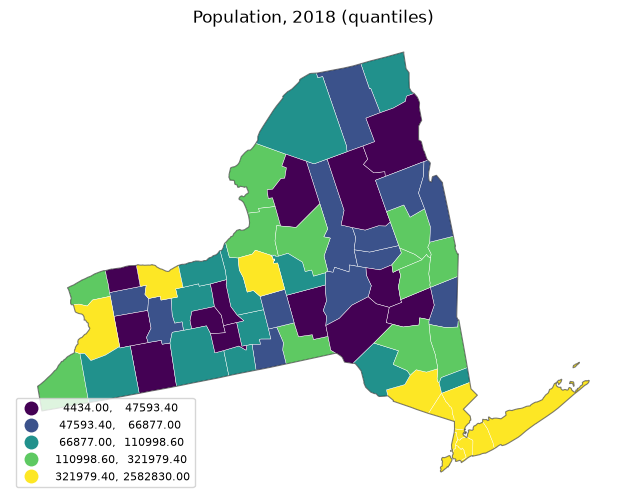

In [10]:
# Map 2018 population with quantile classification and a viridis colormap.
choropleth(counties, "pop", "Population, 2018 (quantiles)", cmap="viridis")  # population choropleth
plt.show()  # render the figure



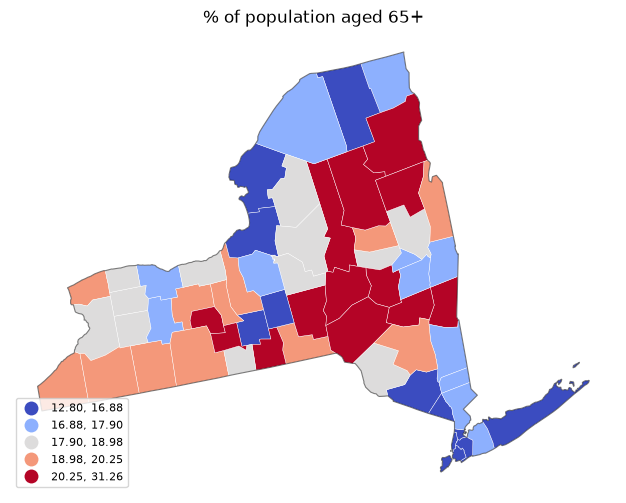

In [11]:
# Derive percent of population aged 65+ and map it.
counties["pct65"] = 100 * counties["pop65"] / counties["pop"]  # elderly share (%)

choropleth(counties, "pct65", "% of population aged 65+", cmap="coolwarm")  # elderly-share map
plt.show()  # render the figure



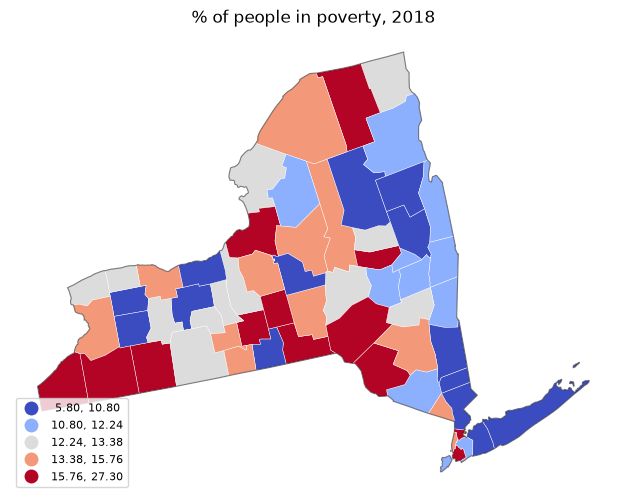

In [12]:
# Map 2018 poverty rate with the default coolwarm colormap.
choropleth(counties, "poverty_pct", "% of people in poverty, 2018", cmap="coolwarm")  # poverty map
plt.show()  # render the figure



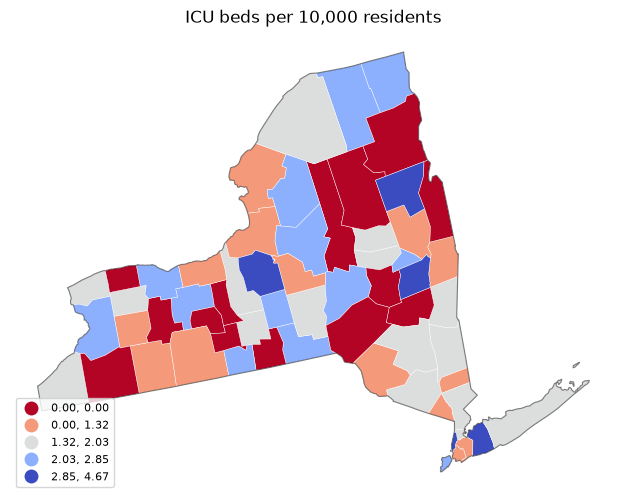

In [13]:
# Derive ICU beds per 10,000 residents and map with natural breaks.
counties["icu_per_10k"] = 10_000 * counties["icu_beds"] / counties["pop"]  # capacity rate

# Map ICU capacity with reversed coolwarm so low capacity reads as warm colours.
choropleth(counties, "icu_per_10k", "ICU beds per 10,000 residents",
           cmap="coolwarm_r", scheme="naturalbreaks")  # natural breaks classification
plt.show()  # render the figure




The rural-urban continuum code is an **ordinal categorical** variable, so it is mapped with a categorical legend instead of a classification scheme.

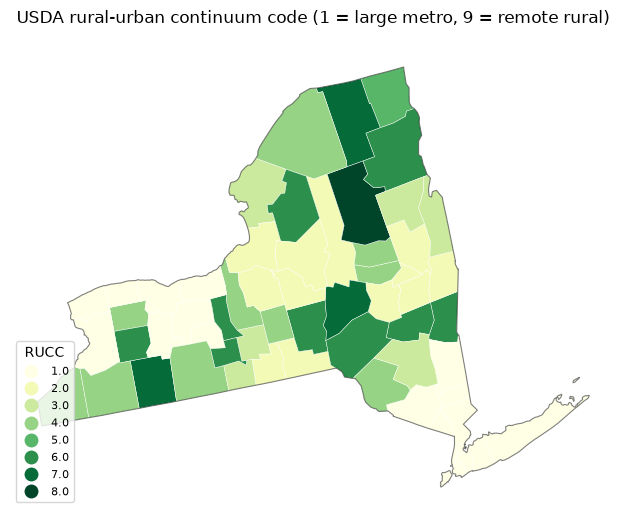

In [14]:
# Map USDA RUCC as an ordinal categorical variable (1 = metro, 9 = remote rural).
ax = counties.plot("rucc", categorical=True, cmap="YlGn", legend=True,
                   edgecolor="white", linewidth=0.3,  # county edges
                   legend_kwds={"title": "RUCC", "loc": "lower left", "fontsize": 8})  # legend
state.boundary.plot(ax=ax, color="#00000080", linewidth=0.8)  # state outline
ax.set_title("USDA rural-urban continuum code (1 = large metro, 9 = remote rural)")  # title
ax.set_axis_off()  # hide axis ticks
plt.show()  # render the figure



**Observations**

- The oldest populations are in the Adirondacks and North Country (Hamilton, Essex) and in the Catskills and upper Hudson Valley (Delaware, Columbia, Greene).
- Poverty is highest in the Bronx and Brooklyn, and in the western Southern Tier (Chautauqua, Cattaraugus, Allegany) and Broome County.
- ICU capacity is concentrated in Manhattan and in the regional centers of Albany, Syracuse, Buffalo, and Long Island, with Warren County (Glens Falls) as a smaller hub.
- The most rural counties (RUCC 6 and above) are scattered across the Southern Tier, the North Country, and the Catskills.

These patterns already suggest where the criteria will agree and where they will conflict.

### Save the cleaned layer

A **GeoPackage** (`.gpkg`) is an open, single-file format that stores geometry, attributes, and the CRS together. Module 2 starts from this file.

In [15]:
# Persist the cleaned county GeoDataFrame and dissolved state outline to GeoPackage.
out = DATA_DIR / "ny_counties.gpkg"  # shared output used by later MCSM notebooks
counties.to_file(str(out), layer="counties", driver="GPKG")  # write county polygons + attributes
state.to_file(str(out), layer="state", driver="GPKG")  # write dissolved state outline layer
print("Saved:", out)  # confirm output path
counties.drop(columns="geometry").head()  # preview attribute columns without geometry



Saved: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/MCSM_data/ny_counties.gpkg


,GEOID,county,state,pop,pop65,poverty_pct,icu_beds,rucc,pct65,icu_per_10k
0,36003,Allegany County,NY,46430,8815.0,17.0,6.0,7.0,18.985570,1.292268
1,36021,Columbia County,NY,59916,14255.0,11.7,9.0,6.0,23.791642,1.502103
2,36037,Genesee County,NY,57511,10750.0,9.9,10.0,4.0,18.692076,1.738798
3,36043,Herkimer County,NY,61833,12815.0,13.5,0.0,2.0,20.725179,0.000000
4,36057,Montgomery County,NY,49455,9203.0,15.8,8.0,4.0,18.608836,1.617632


## Exercises

1. Change `STATE` to another state, such as `"PA"`, and filter the polygons with that state's FIPS code (`"42"`). Do all counties join?
2. Redraw the poverty map with `scheme="naturalbreaks"` and `scheme="equalinterval"`. How does the visual story change?
3. Find two other columns in the summary table that could serve as health-care criteria. What direction (higher or lower is better) would each have?

## Key takeaways

- Suitability analysis treats every location as an alternative and every layer as a criterion.
- Federal data are linked through **FIPS codes**. Store them as zero-padded text.
- Always check row counts after a join, and reproject to a meter-based, equal-area CRS before measuring.
- The classification scheme changes how a choropleth reads, so choose it deliberately.

**Next: Module 2: Deriving Criteria: Indices, Spatial Joins, and Distance.**